In [4]:
from google.colab import files
uploaded = files.upload()



Saving employee_pay_equity_messy.csv to employee_pay_equity_messy (2).csv


In [5]:
import  pandas as pd
df_raw = pd.read_csv("employee_pay_equity_messy.csv")

Step 1 — Foundations & Problem Framing (Unit 1)

In [6]:
print("Rows, columns:", df_raw.shape)
print("\nColumn names:")
print(df_raw.columns.tolist())
print("\nData types:")
display(df_raw.dtypes.to_frame("dtype"))
print("\nDataset information:")
df_raw.info()

Rows, columns: (42686, 19)

Column names:
['employee_id', 'full_name', 'source_dataset', 'age', 'gender', 'ethnicity', 'education_level', 'years_experience', 'tenure_years', 'department', 'job_title', 'country', 'remote_status', 'performance_rating', 'performance_review_score', 'hire_date', 'currency', 'salary_raw', 'pay_band']

Data types:


,dtype
employee_id,object
full_name,object
source_dataset,object
age,float64
gender,object
ethnicity,object
education_level,object
years_experience,float64
tenure_years,float64
department,object



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42686 entries, 0 to 42685
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   employee_id               42686 non-null  object 
 1   full_name                 42686 non-null  object 
 2   source_dataset            42686 non-null  object 
 3   age                       41367 non-null  float64
 4   gender                    41392 non-null  object 
 5   ethnicity                 31929 non-null  object 
 6   education_level           40634 non-null  object 
 7   years_experience          42280 non-null  float64
 8   tenure_years              42280 non-null  float64
 9   department                42686 non-null  object 
 10  job_title                 42686 non-null  object 
 11  country                   42686 non-null  object 
 12  remote_status             37896 non-null  object 
 13  performance_rating        40542 non-nul

In [7]:
display(df_raw.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
employee_id,42686,42686,E145770,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
full_name,42686,34848,John Smith,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_dataset,42686,3,hris_export_2023,21484,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,41367.0,NaN,NaN,NaN,35.612904,8.635482,20.0,29.0,35.0,42.0,68.0
gender,41392,15,MALE,4487,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ethnicity,31929,8,White,14409,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_level,40634,10,PhD,4146,NaN,NaN,NaN,NaN,NaN,NaN,NaN
years_experience,42280.0,NaN,NaN,NaN,14.699125,8.686301,0.0,8.0,14.0,21.0,40.0
tenure_years,42280.0,NaN,NaN,NaN,2.923865,2.558208,0.0,1.0,3.0,5.0,16.0
department,42686,24,IT,3593,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
unique_summary = pd.DataFrame({
    "column": df_raw.columns,
    "unique_values": [df_raw[c].nunique(dropna=True) for c in df_raw.columns],
    "missing_values": [df_raw[c].isna().sum() for c in df_raw.columns],
    "missing_percent": [df_raw[c].isna().mean()*100 for c in df_raw.columns]
}).sort_values("missing_percent", ascending=False)
display(unique_summary)

,column,unique_values,missing_values,missing_percent
5,ethnicity,8,10757,25.200300
14,performance_review_score,41,6712,15.724125
12,remote_status,8,4790,11.221478
13,performance_rating,6,2144,5.022724
6,education_level,10,2052,4.807197
3,age,49,1319,3.090006
4,gender,15,1294,3.031439
8,tenure_years,17,406,0.951132
7,years_experience,41,406,0.951132
17,salary_raw,42038,1,0.002343


In [9]:
import numpy as np
import pandas as pd

numeric_cols = df_raw.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df_raw.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Numeric columns: ['age', 'years_experience', 'tenure_years', 'performance_review_score']
Categorical columns: ['employee_id', 'full_name', 'source_dataset', 'gender', 'ethnicity', 'education_level', 'department', 'job_title', 'country', 'remote_status', 'performance_rating', 'hire_date', 'currency', 'salary_raw', 'pay_band']


Step 2 — Data Handling with NumPy & Pandas (Unit 2)

In [10]:
display(df_raw[["employee_id", "department", "job_title", "country"]].head())
display(df_raw.loc[0:4, ["employee_id", "age", "gender"]])
display(df_raw.iloc[0:5, 0:6])

,employee_id,department,job_title,country
0,E145770,Finance,Controller,Germany
1,E181146,Sales,Sales Manager,India
2,E155936,Marketing,Marketing Manager,Germany
3,E133644,Marketing,SEO Specialist,Singapore
4,E192474,Operations,Logistics Coordinator,Nigeria


,employee_id,age,gender
0,E145770,43.0,Female
1,E181146,37.0,Female
2,E155936,39.0,Man
3,E133644,38.0,Man
4,E192474,30.0,female


,employee_id,full_name,source_dataset,age,gender,ethnicity
0,E145770,Kenneth Alexander,survey_response_2024,43.0,Female,Black or African American
1,E181146,Cory Warner,survey_response_2024,37.0,Female,White
2,E155936,April Leon,hris_export_2023,39.0,Man,Black or African American
3,E133644,Jamie Garcia,hris_export_2023,38.0,Man,White
4,E192474,Jamie Robinson,survey_response_2024,30.0,female,NaN


In [11]:
experienced = df_raw[df_raw["years_experience"] >= 5]
engineering = df_raw[df_raw["department"].astype(str).str.contains("engineering", case=False, na=False)]
print("Employees with >= 5 years experience:", len(experienced))
print("Engineering department rows:", len(engineering))
display(experienced.head())

Employees with >= 5 years experience: 36467
Engineering department rows: 3570


,employee_id,full_name,source_dataset,age,gender,ethnicity,education_level,years_experience,tenure_years,department,job_title,country,remote_status,performance_rating,performance_review_score,hire_date,currency,salary_raw,pay_band
0,E145770,Kenneth Alexander,survey_response_2024,43.0,Female,Black or African American,Associate Degree,25.0,0.0,Finance,Controller,Germany,Hybrid,Meets Expectations,3.6,2026/05/12,EUR,"€41,185",Band 2
1,E181146,Cory Warner,survey_response_2024,37.0,Female,White,PhD.,18.0,1.0,Sales,Sales Manager,India,remote,Meets Expectations,4.0,2024/12/05,INR,"4,715,450 INR",Band 3
2,E155936,April Leon,hris_export_2023,39.0,Man,Black or African American,High School,15.0,5.0,Marketing,Marketing Manager,Germany,Remote,Meets Expectations,NaN,2021-05-15,EUR,"61,833.17",Band 3
3,E133644,Jamie Garcia,hris_export_2023,38.0,Man,White,Master's,19.0,0.0,Marketing,SEO Specialist,Singapore,On-site,Meets Expectations,4.8,2025-11-30,SGD,"41,219.59",Band 1
4,E192474,Jamie Robinson,survey_response_2024,30.0,female,NaN,PhD.,10.0,7.0,Operations,Logistics Coordinator,Nigeria,REMOTE,Below Expectations,4.2,30 Apr 2019,NGN,"55,659,714 NGN",Band 1


In [12]:
display(df_raw.sort_values("years_experience", ascending=False).head(10))
display(df_raw["department"].value_counts(dropna=False).head(15))
display(df_raw["country"].value_counts().head(15))
display(df_raw["pay_band"].value_counts(dropna=False))

,employee_id,full_name,source_dataset,age,gender,ethnicity,education_level,years_experience,tenure_years,department,job_title,country,remote_status,performance_rating,performance_review_score,hire_date,currency,salary_raw,pay_band
36257,E192125,Katrina Wright,hris_export_2023,61.0,M,Black or African American,NaN,40.0,6.0,Finance,Accountant,UK,Hybrid,Exceeds Expectations,NaN,01 Aug 2020,GBP,"40,282.89",Band 2
23712,E191201,John Mahoney,survey_response_2024,59.0,male,Asian,High School,40.0,4.0,Design,VP Design,South Africa,On site,Exceeds Expectations,2.8,15/05/2022,ZAR,"1,972,935 ZAR",Band 4
42628,E179043,Kurt Chambers,survey_response_2024,68.0,F,Native American,Master's,40.0,10.0,HR,VP People,Australia,On site,Exceeds Expectations,NaN,2016-03-02,AUD,"130,949 AUD",Band 4
23606,E124506,Elizabeth Cox,survey_response_2024,59.0,Male,Native American,Bachelor's,40.0,4.0,Finance,Financial Analyst,India,On site,Meets Expectations,3.2,16/12/2021,INR,"4,041,229 INR",Band 3
45,E101938,Diana Johnson,hris_export_2023,64.0,female,Hispanic or Latino,Bachelors,40.0,3.0,Finance,Controller,Brazil,Onsite,Meets Expectations,NaN,09 Mar 2023,BRL,"212,686.21",Band 2
21098,E151269,Jason Mendez,hris_export_2023,63.0,Male,White,bachelor's degree,40.0,3.0,Data Science,ML Engineer,South Africa,hybrid,Meets Expectations,2.6,2023-06-11,ZAR,"1,325,452.54",Band 3
23353,E122306,Brittany Campos,survey_response_2024,61.0,male,White,Bachelors,40.0,6.0,IT,Systems Administrator,United Kingdom,On site,NaN,4.0,11/11/2019,GBP,"£56,260",Band 3
20656,E157538,Jennifer Bernard,survey_response_2024,59.0,F,Hispanic or Latino,Bachelor's,40.0,4.0,Customer Support,Customer Success Manager,Netherlands,remote,Meets Expectations,3.0,2022-03-13,EUR,"€73,453",Band 4
1539,E125535,Jacqueline Vasquez,survey_response_2024,64.0,Woman,NaN,PhD,40.0,2.0,Data Science,ML Engineer,Kenya,On site,Meets Expectations,NaN,22 Feb 2024,KES,"5,713,354 KES",Band 2
37256,LEG-39083,William Mann,acquired_company_legacy,66.0,Female,NaN,Master's,40.0,4.0,Marketing,CMO,India,Onsite,Exceeds Expectations,3.1,2022/06/08,INR,10794717,Band 4


,count
department,
IT,3593
Sales,3558
Finance,3553
Marketing,3546
HR,3540
Customer Support,3536
Engineering,3535
Design,3515
Data Science,3492


,count
country,
Germany,2597
Kenya,2580
South Africa,2575
Australia,2563
Philippines,2551
USA,2547
United States,2520
US,2519
Brazil,2500


,count
pay_band,
Band 2,16896
Band 1,16578
Band 3,8454
Band 4,748
Band 5,9
NaN,1


In [13]:
display(pd.crosstab(df_raw["department"], df_raw["pay_band"], margins=True))
display(pd.pivot_table(df_raw, index="department", columns="remote_status",
                       values="employee_id", aggfunc="count", fill_value=0))

pay_band,Band 1,Band 2,Band 3,Band 4,Band 5,All
department,,,,,,
Customer Support,977,1669,850,40,0,3536
Data Science,1487,1507,478,20,0,3492
Design,1299,1569,622,25,0,3515
Engineering,1511,1560,444,20,0,3535
Finance,1403,1333,765,52,0,3553
HR,1418,1325,758,39,0,3540
IT,1596,1339,617,41,0,3593
Legal,2192,1184,36,0,0,3412
Marketing,1364,1398,721,61,1,3545


remote_status,Hybrid,On site,On-site,Onsite,REMOTE,Remote,hybrid,remote
department,,,,,,,,
Customer Support,399,389,386,422,342,396,404,404
Data Science,384,393,410,357,397,381,384,389
Design,387,402,375,392,402,365,378,402
Engineering,388,368,426,387,388,397,409,393
Finance,387,389,412,387,374,387,392,408
HR,430,362,380,416,392,366,358,412
IT,397,394,407,401,402,392,382,409
Legal,403,394,339,363,359,391,381,398
Marketing,410,355,380,373,408,396,403,414


In [14]:
dept_counts = df_raw.groupby("department").size().reset_index(name="department_employee_count")
df_with_dept_count = df_raw.merge(dept_counts, on="department", how="left")
display(df_with_dept_count[["employee_id", "department", "department_employee_count"]].head())

,employee_id,department,department_employee_count
0,E145770,Finance,3553
1,E181146,Sales,3558
2,E155936,Marketing,3546
3,E133644,Marketing,3546
4,E192474,Operations,3492


In [15]:
df_raw.head(100).to_csv("employee_sample.csv", index=False)
sample_read = pd.read_csv("employee_sample.csv")
print("Read-back shape:", sample_read.shape)
with open("project_notes.txt", "w") as f:
    f.write("Employee Pay Equity Analysis - project notes")
print("CSV and text examples saved in the Colab session.")

Read-back shape: (100, 19)
CSV and text examples saved in the Colab session.


Step 3 — Preprocessing & Analysis (Unit 3, PBL)

In [16]:
df = df_raw.copy()
print("Original rows:", len(df))
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate employee IDs:", df["employee_id"].duplicated().sum())

Original rows: 42686
Exact duplicate rows: 0
Duplicate employee IDs: 0


In [17]:
df = df.drop_duplicates().copy()
duplicate_ids = df[df["employee_id"].duplicated(keep=False)].sort_values("employee_id")
print("Rows after exact duplicate removal:", len(df))
print("Rows belonging to repeated employee IDs:", len(duplicate_ids))
display(duplicate_ids.head(10))

Rows after exact duplicate removal: 42686
Rows belonging to repeated employee IDs: 0


,employee_id,full_name,source_dataset,age,gender,ethnicity,education_level,years_experience,tenure_years,department,job_title,country,remote_status,performance_rating,performance_review_score,hire_date,currency,salary_raw,pay_band


In [18]:
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean()*100).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing_report)

,missing_count,missing_percent
ethnicity,10757,25.20
performance_review_score,6712,15.72
remote_status,4790,11.22
performance_rating,2144,5.02
education_level,2052,4.81
age,1319,3.09
gender,1294,3.03
tenure_years,406,0.95
years_experience,406,0.95
employee_id,0,0.00


In [19]:
for col in ["age", "gender", "ethnicity", "education_level", "years_experience",
            "tenure_years", "remote_status", "performance_rating",
            "performance_review_score"]:
    if col in df.columns:
        df[col + "_was_missing"] = df[col].isna().astype(int)

num_for_fill = df.select_dtypes(include=np.number).columns
for col in num_for_fill:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

cat_for_fill = df.select_dtypes(include=["object", "category"]).columns
for col in cat_for_fill:
    if df[col].isna().any():
        mode = df[col].mode(dropna=True)
        fill_value = mode.iloc[0] if len(mode) else "Unknown"
        df[col] = df[col].fillna(fill_value)

print("Missing values remaining:", int(df.isna().sum().sum()))

Missing values remaining: 0


In [20]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype(str).str.strip()

df["hire_date"] = pd.to_datetime(df["hire_date"], errors="coerce")
print("Invalid hire dates:", df["hire_date"].isna().sum())
df["hire_year"] = df["hire_date"].dt.year
df["hire_month"] = df["hire_date"].dt.month
df["hire_quarter"] = df["hire_date"].dt.quarter
display(df[["hire_date", "hire_year", "hire_month", "hire_quarter"]].head())

Invalid hire dates: 34092


,hire_date,hire_year,hire_month,hire_quarter
0,2026-05-12,2026.0,5.0,2.0
1,2024-12-05,2024.0,12.0,4.0
2,NaT,NaN,NaN,NaN
3,NaT,NaN,NaN,NaN
4,NaT,NaN,NaN,NaN


In [21]:
def iqr_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5*iqr, q3 + 1.5*iqr

for col in ["age", "years_experience", "tenure_years", "performance_review_score"]:
    low, high = iqr_bounds(df[col])
    flag = (df[col] < low) | (df[col] > high)
    print(f"{col}: lower={low:.2f}, upper={high:.2f}, flagged={flag.sum()}")

age: lower=13.50, upper=57.50, flagged=271
years_experience: lower=-11.50, upper=40.50, flagged=0
tenure_years: lower=-5.00, upper=11.00, flagged=68
performance_review_score: lower=1.40, upper=5.40, flagged=396


In [22]:
import re
import pandas as pd

def clean_salary(val):
    if pd.isna(val):
        return None
    cleaned = re.sub(r'[\d\.]+', lambda m: m.group(0), str(val))
    numeric_str = ''.join(c for c in cleaned if c.isdigit() or c == '.')
    try:
        return float(numeric_str) if numeric_str else None
    except ValueError:
        return None

if 'salary_amount' not in df.columns:
    df['salary_amount'] = df['salary_raw'].apply(clean_salary)

def add_salary_outlier_flag(group):
    s = group["salary_amount"]
    if s.notna().sum() < 4:
        group["salary_outlier_flag"] = False
    else:
        lo, hi = iqr_bounds(s.dropna())
        group["salary_outlier_flag"] = (s < lo) | (s > hi)
    return group

df = df.groupby("currency", group_keys=False).apply(add_salary_outlier_flag)
display(df[df["salary_outlier_flag"]][["employee_id", "job_title", "country",
                                      "currency", "salary_amount"]].head(20))

/tmp/ipykernel_810/3610288171.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby("currency", group_keys=False).apply(add_salary_outlier_flag)


,employee_id,job_title,country,currency,salary_amount
53,E146626,IT Manager,Kenya,KES,11745271.71
189,E187275,Sales Manager,UK,GBP,72058.59
197,E156788,IT Manager,USA,USD,106099.24
204,E189122,COO,Germany,EUR,112705.00
205,E128291,Finance Manager,Singapore,SGD,120755.00
477,E174161,Marketing Manager,United Kingdom,GBP,94645.33
676,E131774,Head of Data,US,USD,90295.07
713,E136739,Finance Manager,US,USD,11022793.00
852,E105705,COO,United States,USD,100577.00
884,E119212,VP Product,US,USD,889201.73


In [23]:
encoding_source = df[["remote_status", "education_level"]].astype(str)
encoded_demo = pd.get_dummies(encoding_source, columns=["remote_status", "education_level"],
                             dtype=int)
display(encoded_demo.head())
print("Encoded shape:", encoded_demo.shape)

,remote_status_Hybrid,remote_status_On site,remote_status_On-site,remote_status_Onsite,remote_status_REMOTE,remote_status_Remote,remote_status_hybrid,remote_status_remote,education_level_Associate Degree,education_level_BSc,education_level_Bachelor's,education_level_Bachelors,education_level_High School,education_level_MSc,education_level_Master's,education_level_PhD,education_level_PhD.,education_level_bachelor's degree
0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
2,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0
3,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
4,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0


Encoded shape: (42686, 18)


In [24]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder

scale_cols = ["age", "years_experience", "tenure_years", "performance_review_score"]
X_scale = df[scale_cols].astype(float)
standardized = StandardScaler().fit_transform(X_scale)
normalized = MinMaxScaler().fit_transform(X_scale)

standardized_df = pd.DataFrame(standardized, columns=[c+"_z" for c in scale_cols])
normalized_df = pd.DataFrame(normalized, columns=[c+"_minmax" for c in scale_cols])
display(pd.concat([standardized_df.head(), normalized_df.head()], axis=1))

,age_z,years_experience_z,tenure_years_z,performance_review_score_z,age_minmax,years_experience_minmax,tenure_years_minmax,performance_review_score_minmax
0,0.871137,1.192303,-1.148702,0.264464,0.479167,0.625,0.0000,0.65
1,0.165385,0.382591,-0.755928,0.766292,0.354167,0.450,0.0625,0.75
2,0.400636,0.035572,0.815167,0.013549,0.395833,0.375,0.3125,0.60
3,0.283010,0.498264,-1.148702,1.769950,0.375000,0.475,0.0000,0.95
4,-0.657992,-0.542793,1.600715,1.017207,0.208333,0.250,0.4375,0.80


In [25]:
display(df[["age", "years_experience", "tenure_years",
            "performance_review_score", "salary_amount"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
age,42686.0,3.559397e+01,8.501675e+00,20.0,30.0000,35.0,41.0,6.800000e+01
years_experience,42686.0,1.469248e+01,8.645158e+00,0.0,8.0000,14.0,21.0,4.000000e+01
tenure_years,42686.0,2.924589e+00,2.546024e+00,0.0,1.0000,3.0,5.0,1.600000e+01
performance_review_score,42686.0,3.389200e+00,7.970938e-01,1.0,2.9000,3.4,3.9,5.000000e+00
salary_amount,42686.0,5.493952e+06,8.697034e+07,156.0,38051.5525,60255.0,1024787.0,1.392384e+10


In [26]:
corr_cols = ["age", "years_experience", "tenure_years",
             "performance_review_score", "salary_amount"]
corr = df[corr_cols].corr(numeric_only=True)
display(corr.round(2))

,age,years_experience,tenure_years,performance_review_score,salary_amount
age,1.00,0.95,0.20,0.00,0.01
years_experience,0.95,1.00,0.20,0.00,0.01
tenure_years,0.20,0.20,1.00,-0.01,-0.00
performance_review_score,0.00,0.00,-0.01,1.00,0.00
salary_amount,0.01,0.01,-0.00,0.00,1.00


In [27]:
salary_by_department = df.groupby(["currency", "department"]).agg(
    employee_count=("employee_id", "count"),
    median_salary=("salary_amount", "median"),
    mean_experience=("years_experience", "mean"),
    median_performance=("performance_review_score", "median")
).reset_index()
display(salary_by_department.sort_values("employee_count", ascending=False).head(30))

,currency,department,employee_count,median_salary,mean_experience,median_performance
229,USD,IT,679,39714.040,14.343152,3.4
224,USD,Data Science,659,40756.000,14.913505,3.4
73,EUR,Marketing,653,38763.000,15.049005,3.4
68,EUR,Engineering,652,37045.425,14.667178,3.4
76,EUR,Sales,650,38038.090,14.206154,3.4
70,EUR,HR,644,37718.165,14.094720,3.4
231,USD,Marketing,641,43126.670,14.868955,3.4
223,USD,Customer Support,639,46269.000,14.738654,3.4
228,USD,HR,631,41376.000,14.356577,3.4
67,EUR,Design,631,38691.000,14.730586,3.4


In [28]:
display(pd.crosstab(df["gender"], df["pay_band"], normalize="index").round(3))

pay_band,Band 1,Band 2,Band 3,Band 4,Band 5
gender,,,,,
F,0.392,0.399,0.192,0.017,0.001
FEMALE,0.380,0.403,0.204,0.012,0.000
Female,0.390,0.393,0.194,0.023,0.000
M,0.395,0.384,0.203,0.017,0.000
MALE,0.382,0.402,0.200,0.015,0.000
Male,0.396,0.383,0.206,0.016,0.000
Man,0.388,0.389,0.203,0.020,0.000
NB,0.401,0.356,0.226,0.017,0.000
Non-binary,0.363,0.427,0.188,0.022,0.000


In [29]:
main_currency = df["currency"].value_counts().idxmax()
currency_subset = df[df["currency"] == main_currency]
print("Most frequent currency:", main_currency, "| rows:", len(currency_subset))
display(currency_subset[["salary_amount", "age", "years_experience",
                         "tenure_years", "performance_review_score"]].corr().round(2))

Most frequent currency: USD | rows: 7587


,salary_amount,age,years_experience,tenure_years,performance_review_score
salary_amount,1.00,0.06,0.07,0.01,0.01
age,0.06,1.00,0.96,0.20,0.02
years_experience,0.07,0.96,1.00,0.20,0.03
tenure_years,0.01,0.20,0.20,1.00,-0.01
performance_review_score,0.01,0.02,0.03,-0.01,1.00


In [30]:

correlation = df.corr(numeric_only=True)

print("Correlation Matrix:")
display(correlation)


Correlation Matrix:


,age,years_experience,tenure_years,performance_review_score,age_was_missing,gender_was_missing,ethnicity_was_missing,education_level_was_missing,years_experience_was_missing,tenure_years_was_missing,remote_status_was_missing,performance_rating_was_missing,performance_review_score_was_missing,hire_year,hire_month,hire_quarter,salary_amount,salary_outlier_flag
age,1.000000,0.953421,0.198760,0.001126,-0.012475,0.001180,-0.002058,-0.010522,-0.005711,0.000109,0.000392,-0.003892,-0.000505,-0.190566,-0.000602,-0.000250,0.013161,0.153946
years_experience,0.953421,1.000000,0.202262,0.002689,-0.001728,0.001785,-0.001192,-0.008398,-0.007849,0.000136,-0.001279,-0.004599,-0.000044,-0.191373,-0.001244,-0.000734,0.014968,0.162532
tenure_years,0.198760,0.202262,1.000000,-0.007016,-0.003644,0.001910,0.005260,0.002140,-0.002691,0.002903,-0.000081,0.009592,0.003492,-0.980991,0.004529,0.006282,-0.003537,0.049449
performance_review_score,0.001126,0.002689,-0.007016,1.000000,0.007837,-0.006587,-0.001816,0.005683,-0.005243,-0.000217,-0.005854,-0.003357,0.005853,0.010039,-0.017433,-0.014013,0.003580,0.002714
age_was_missing,-0.012475,-0.001728,-0.003644,0.007837,1.000000,0.008698,0.007361,-0.009117,-0.002156,-0.004945,0.000853,0.010382,-0.001637,0.007129,-0.014440,-0.015319,0.012475,0.004421
gender_was_missing,0.001180,0.001785,0.001910,-0.006587,0.008698,1.000000,-0.000344,0.004979,0.016460,-0.000433,0.002941,0.001255,0.000574,-0.005504,0.013902,0.012687,-0.000968,-0.010384
ethnicity_was_missing,-0.002058,-0.001192,0.005260,-0.001816,0.007361,-0.000344,1.000000,0.006783,-0.005733,-0.004622,-0.000700,0.003386,0.000379,0.007144,-0.008740,-0.012427,-0.004867,-0.001523
education_level_was_missing,-0.010522,-0.008398,0.002140,0.005683,-0.009117,0.004979,0.006783,1.000000,-0.003968,-0.006225,0.004766,0.005482,-0.001402,-0.012680,-0.013008,-0.011421,-0.002473,-0.000418
years_experience_was_missing,-0.005711,-0.007849,-0.002691,-0.005243,-0.002156,0.016460,-0.005733,-0.003968,1.000000,0.002831,0.000337,0.007302,-0.007850,0.008873,0.000156,-0.000374,-0.001179,-0.004095
tenure_years_was_missing,0.000109,0.000136,0.002903,-0.000217,-0.004945,-0.000433,-0.004622,-0.006225,0.002831,1.000000,-0.001957,-0.000433,-0.001220,-0.003108,0.007973,0.008356,-0.000050,-0.005789


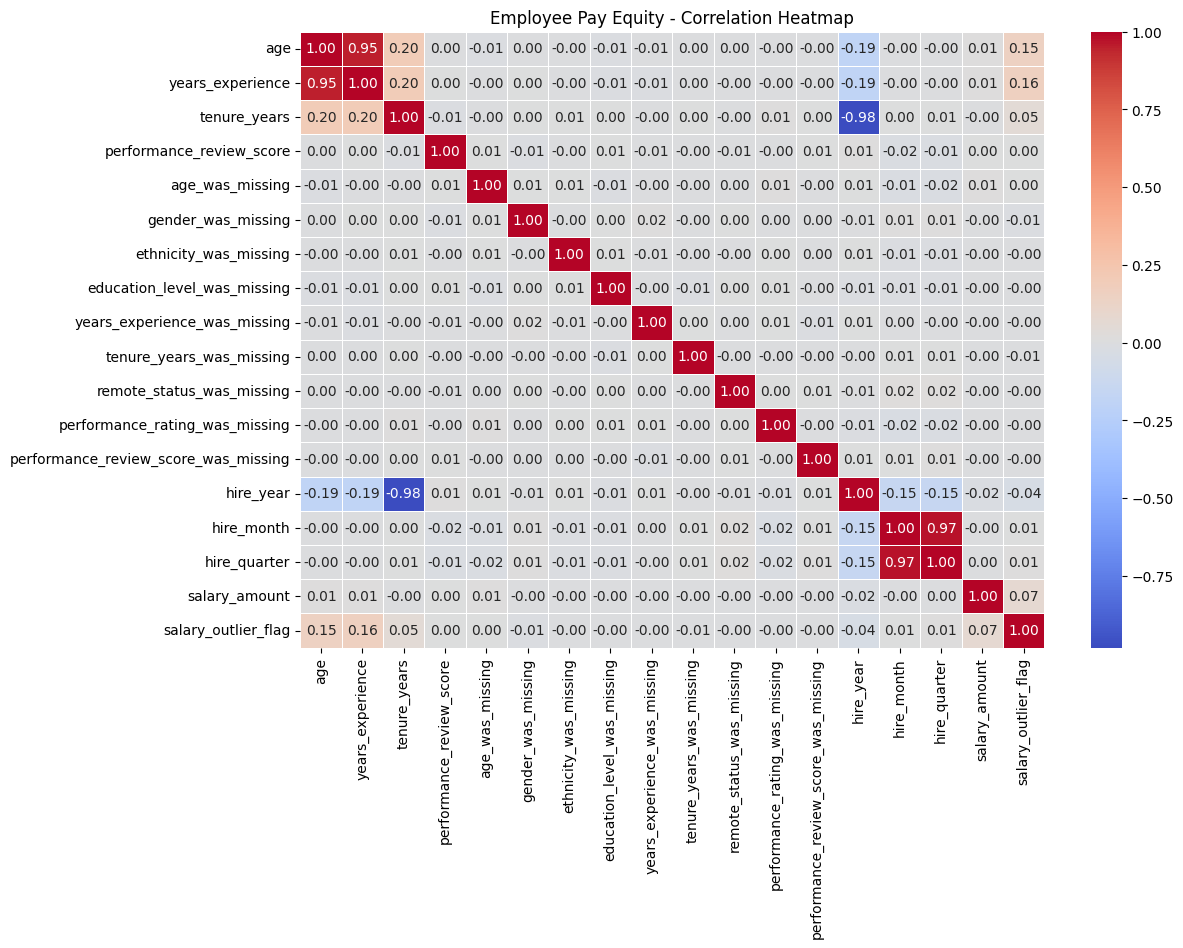

In [31]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Employee Pay Equity - Correlation Heatmap")
plt.show()


In [32]:
salary_corr = df[
    ["salary_amount",
     "age",
     "years_experience",
     "tenure_years",
     "performance_review_score"]
].corr()

display(salary_corr)

print("Correlation with Salary:")
display(salary_corr["salary_amount"].sort_values(ascending=False))


,salary_amount,age,years_experience,tenure_years,performance_review_score
salary_amount,1.000000,0.013161,0.014968,-0.003537,0.003580
age,0.013161,1.000000,0.953421,0.198760,0.001126
years_experience,0.014968,0.953421,1.000000,0.202262,0.002689
tenure_years,-0.003537,0.198760,0.202262,1.000000,-0.007016
performance_review_score,0.003580,0.001126,0.002689,-0.007016,1.000000


Correlation with Salary:


,salary_amount
salary_amount,1.000000
years_experience,0.014968
age,0.013161
performance_review_score,0.003580
tenure_years,-0.003537


In [33]:
df.groupby("department").size()

,0
department,
Customer Support,3536
Data Science,3492
Design,3515
Engineering,3535
Finance,3553
HR,3540
IT,3593
Legal,3412
Marketing,3546


In [34]:
df.groupby("department")["salary_amount"].agg(["mean","max","count"])

,mean,max,count
department,,,
Customer Support,5.376628e+06,9.536706e+08,3536
Data Science,3.992304e+06,1.461611e+08,3492
Design,4.722407e+06,1.220436e+09,3515
Engineering,6.897766e+06,9.092507e+09,3535
Finance,9.029999e+06,1.392384e+10,3553
HR,5.279614e+06,4.753333e+08,3540
IT,4.265120e+06,1.521404e+08,3593
Legal,4.092432e+06,3.239295e+08,3412
Marketing,5.012885e+06,5.163739e+08,3546


In [35]:
average_salary = df["salary_amount"].mean()
high_salary_employees = df[df["salary_amount"] > average_salary]
print(high_salary_employees.head())

   employee_id           full_name        source_dataset   age  gender  \
4      E192474      Jamie Robinson  survey_response_2024  30.0  female   
19     E179375      Kristina Kelly      hris_export_2023  30.0  female   
35     E167985  Mr. Andre Thompson      hris_export_2023  23.0  Female   
44     E101574      Bailey Stewart      hris_export_2023  29.0  FEMALE   
53     E146626        Stacy Franco      hris_export_2023  33.0    male   

             ethnicity education_level  years_experience  tenure_years  \
4                White            PhD.              10.0           7.0   
19  Hispanic or Latino     High School              11.0           5.0   
35               White      Bachelor's               2.0           2.0   
44               White      Bachelor's              10.0           6.0   
53               White      Bachelor's              11.0           1.0   

      department  ... years_experience_was_missing tenure_years_was_missing  \
4     Operations  ...          

QUESTIONS ON Correlation

Question 1: Is there a relationship between employee age and years of experience?

Correlation between Age and Experience: 0.953


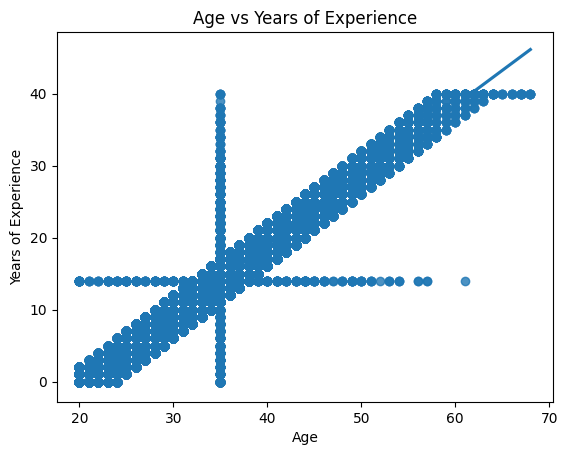

In [36]:
age_exp = df[["age", "years_experience"]].dropna()

correlation = age_exp["age"].corr(
    age_exp["years_experience"],
    method="pearson"
)

print("Correlation between Age and Experience:", round(correlation, 3))

sns.regplot(
    data=age_exp,
    x="age",
    y="years_experience"
)

plt.title("Age vs Years of Experience")
plt.xlabel("Age")
plt.ylabel("Years of Experience")
plt.show()

Question 2: Does an increase in work experience relate to an increase in salary?

Currency used: USD
Correlation between Experience and Salary: 0.067


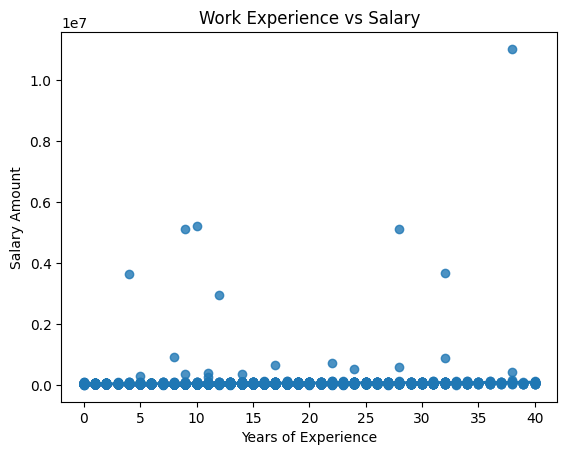

In [37]:
if "salary_amount" not in df.columns:
    if "salary_raw" in df.columns:
        df["salary_amount"] = pd.to_numeric(
            df["salary_raw"].astype(str).str.replace(r"[^0-9.]", "", regex=True),
            errors="coerce"
        )
    else:
        raise ValueError("Salary column not found. Check your dataset columns.")

if "currency" in df.columns:
    common_currency = df["currency"].mode().iloc[0]
    salary_df = df[df["currency"] == common_currency].copy()
    print("Currency used:", common_currency)
else:
    salary_df = df.copy()
    print("Currency column not found. Verify that all salaries use the same currency.")

experience_salary = salary_df[
    ["years_experience", "salary_amount"]
].dropna()

correlation = experience_salary["years_experience"].corr(
    experience_salary["salary_amount"]
)

print("Correlation between Experience and Salary:", round(correlation, 3))

sns.regplot(
    data=experience_salary,
    x="years_experience",
    y="salary_amount"
)

plt.title("Work Experience vs Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary Amount")
plt.show()

Question 3: Is employee tenure related to performance score?

Correlation between Tenure and Performance: -0.007


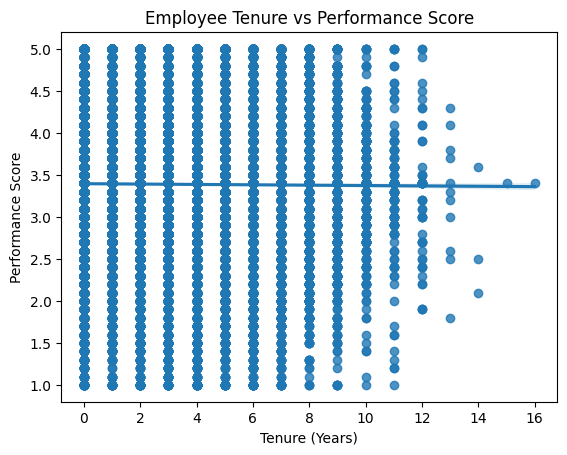

In [38]:
tenure_performance = df[
    ["tenure_years", "performance_review_score"]
].dropna()

correlation = tenure_performance["tenure_years"].corr(
    tenure_performance["performance_review_score"],
    method="pearson"
)

print("Correlation between Tenure and Performance:",
      round(correlation, 3))

sns.regplot(
    data=tenure_performance,
    x="tenure_years",
    y="performance_review_score"
)

plt.title("Employee Tenure vs Performance Score")
plt.xlabel("Tenure (Years)")
plt.ylabel("Performance Score")
plt.show()

Question 4: Does the relationship between experience and salary differ across departments?

/tmp/ipykernel_810/763470057.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


          department  correlation
0   Customer Support     0.477765
1       Data Science     0.413637
2             Design     0.097896
3        Engineering     0.036005
4            Finance     0.105386
5                 HR     0.128603
6                 IT     0.001964
7              Legal     0.393262
8          Marketing     0.159037
9         Operations     0.338510
10           Product     0.288455
11             Sales     0.423437
12  customer support     0.848071
13      data science    -0.975795
14            design     0.250497
15       engineering     0.758100
16           finance     0.872135
17                hr     0.138556
18                it     0.310618
19             legal     0.743955
20         marketing     0.160550
21        operations    -0.091192
22           product     0.037013
23             sales     0.711868


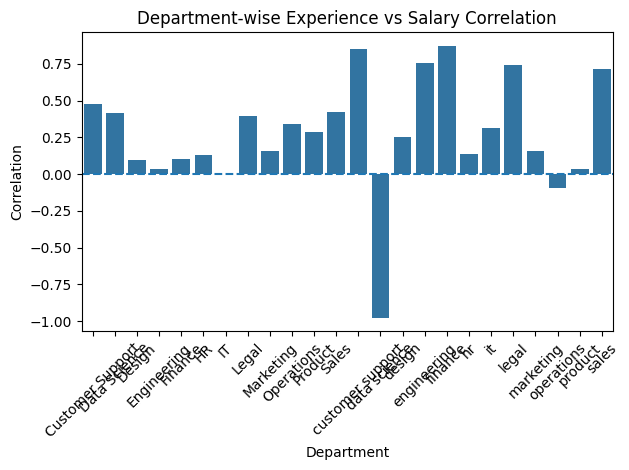

In [39]:
if "department" not in salary_df.columns:
    raise ValueError("Department column not found.")

department_correlation = (
    salary_df.groupby("department")
    .apply(
        lambda group: group["years_experience"].corr(
            group["salary_amount"]
        )
    )
    .dropna()
    .reset_index(name="correlation")
)

print(department_correlation)

sns.barplot(
    data=department_correlation,
    x="department",
    y="correlation"
)

plt.title("Department-wise Experience vs Salary Correlation")
plt.xlabel("Department")
plt.ylabel("Correlation")
plt.xticks(rotation=45)
plt.axhline(0, linestyle="--")
plt.tight_layout()
plt.show()

QUESTIONS ON GROUPING


Q1. How many employees are working in each department?

In [40]:
df.groupby("department").size()

,0
department,
Customer Support,3536
Data Science,3492
Design,3515
Engineering,3535
Finance,3553
HR,3540
IT,3593
Legal,3412
Marketing,3546


Q2. Male and female employees in each department

In [41]:
df.groupby(["department", "gender"]).size()

department        gender
Customer Support  F         296
                  FEMALE    286
                  Female    281
                  M         364
                  MALE      521
                           ... 
sales             Male        6
                  Man         2
                  Woman       4
                  female      3
                  male        5
Length: 301, dtype: int64

Q3. Average salary in each department

In [42]:
df.groupby("department")["salary_amount"].mean()

,salary_amount
department,
Customer Support,5.376628e+06
Data Science,3.992304e+06
Design,4.722407e+06
Engineering,6.897766e+06
Finance,9.029999e+06
HR,5.279614e+06
IT,4.265120e+06
Legal,4.092432e+06
Marketing,5.012885e+06


Q4. Average performance score in each department

In [43]:
df.groupby("department")["performance_review_score"].mean()

,performance_review_score
department,
Customer Support,3.365215
Data Science,3.412314
Design,3.402504
Engineering,3.377992
Finance,3.389896
HR,3.404209
IT,3.391984
Legal,3.372304
Marketing,3.356543


Step 4 — Visualization I (Unit 4, PBL)

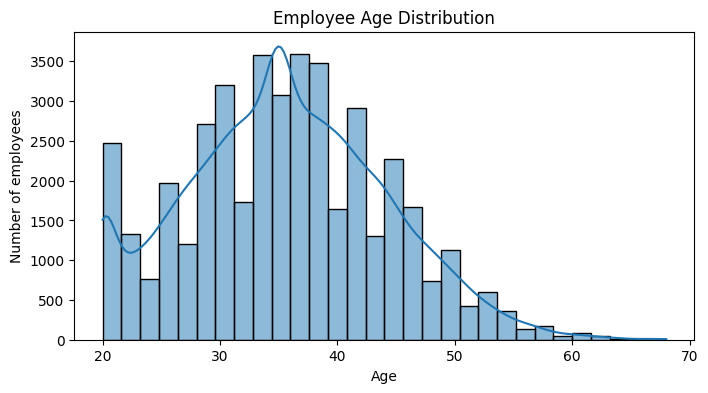

In [44]:
plt.figure(figsize=(8, 4))
sns.histplot(df["age"], bins=30, kde=True)

plt.title("Employee Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of employees")
plt.show()

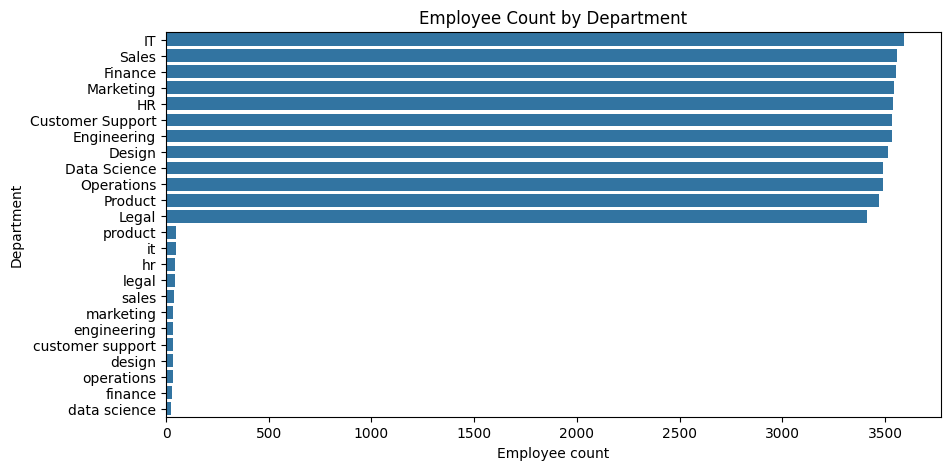

In [45]:
plt.figure(figsize=(10, 5))
order = df["department"].value_counts().index
sns.countplot(data=df, y="department", order=order)
plt.title("Employee Count by Department")
plt.xlabel("Employee count")
plt.ylabel("Department")
plt.show()

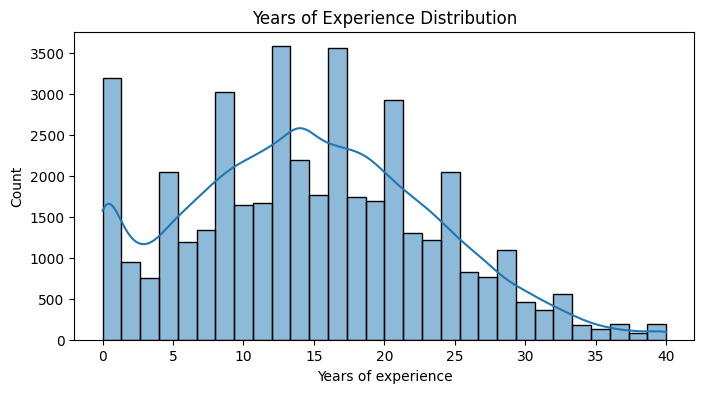

In [46]:
plt.figure(figsize=(8, 4))
sns.histplot(df["years_experience"], bins=30, kde=True)
plt.title("Years of Experience Distribution")
plt.xlabel("Years of experience")
plt.show()

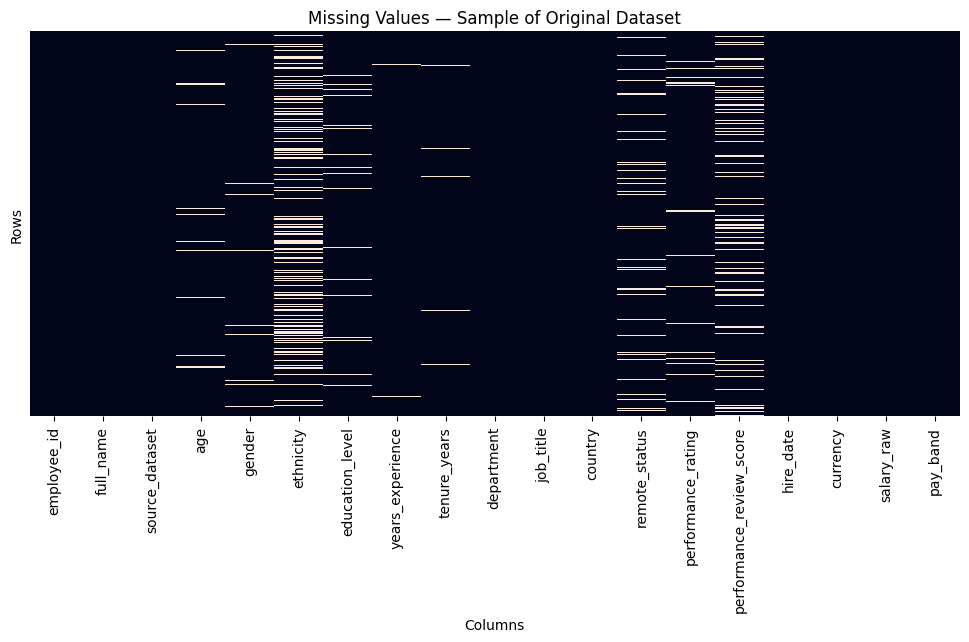

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.heatmap(
    df_raw.sample(min(1500, len(df_raw)), random_state=42).isna(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values — Sample of Original Dataset")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.show()

Most common currency identified: USD


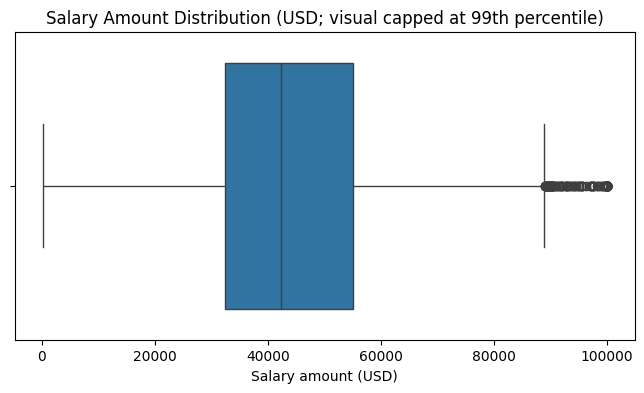

In [48]:
import re
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def clean_salary(val):
    if pd.isna(val):
        return None
    cleaned = re.sub(r'[\d\.]+', lambda m: m.group(0), str(val))
    numeric_str = ''.join(c for c in cleaned if c.isdigit() or c == '.')
    try:
        return float(numeric_str) if numeric_str else None
    except ValueError:
        return None

df['salary_amount'] = df['salary_raw'].apply(clean_salary)

main_currency = df['currency'].value_counts().index[0]
print(f"Most common currency identified: {main_currency}")

currency_subset = df[df['currency'] == main_currency].copy()
plot_df = currency_subset[currency_subset['salary_amount'].notna()].copy()

if len(plot_df):
    upper = plot_df['salary_amount'].quantile(0.99)
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=plot_df['salary_amount'].clip(upper=upper))
    plt.title(f"Salary Amount Distribution ({main_currency}; visual capped at 99th percentile)")
    plt.xlabel(f"Salary amount ({main_currency})")
    plt.show()
else:
    print("No valid salary amounts found to plot.")

STEP 5

In [49]:
!pip -q install plotly statsmodels ipywidgets

import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

from plotly.subplots import make_subplots
from sklearn.ensemble import RandomForestRegressor
from ipywidgets import interact, FloatSlider, IntSlider
from IPython.display import display

# Use the cleaned dataset already created in Step 3
main_currency = df["currency"].value_counts().idxmax()

# Use one currency for fair salary comparisons
currency_subset = df[df["currency"] == main_currency].copy()

print("Dashboard dataset ready!")
print("Total employee records:", len(df))
print("Salary currency used:", main_currency)

Dashboard dataset ready!
Total employee records: 42686
Salary currency used: USD


In [50]:
from google.colab import files
df_raw.to_csv("cleaned_dataset_employee_pay_equity_messy.csv", index=False)
files.download("cleaned_dataset_employee_pay_equity_messy.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>